# Sequential MNIST: Long-Term Dependency Learning Task

This notebook implements the sequential MNIST problem, a benchmark task for evaluating the ability of RNNs to learn long-term dependencies.

## Task Description

We will compare the performance of two network architectures:

1. **Net**: RNN with excitatory/inhibitory separation
2. **SimpleNet**: Standard vanilla RNN


## 1. Setup and Imports


In [9]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
import warnings
warnings.filterwarnings('ignore')
import torchvision
import torchvision.transforms as transforms
# from pdm_model import Net, SimpleNet, EI_Linear
from net.common import init_model, EISepNet, SimpleNet, DANN, DBPN, ColEI

# Set device
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Using device: {device}")

Using device: cuda


## 2. Adding Problem Dataset


In [ ]:
ROW_FACTOR = 1  # Factor to reduce the number of rows in the flattened image
class SequentialMNIST(Dataset):

    def __init__(self, MNIST_dataset: torchvision.datasets.MNIST):
        self.MNIST_dataset = MNIST_dataset

    def __len__(self):
        return len(self.MNIST_dataset)

    def __getitem__(self, idx: int):
        image, target = self.MNIST_dataset[idx]

        # Return flattened image in shape (time steps = 28, dimensionality = 28)
        row_factor = ROW_FACTOR
        return image.view(28*row_factor, 28//row_factor), target

MNIST_MEAN = 0.1307
# MNIST_MEAN = 0.0
MNIST_STD = 0.3081

mnist_transforms = transforms.Compose([transforms.ToTensor(), transforms.Normalize((MNIST_MEAN,), (MNIST_STD,))])
train_dataset = SequentialMNIST(torchvision.datasets.MNIST('.', train=True, download=True, transform=mnist_transforms))
test_dataset = SequentialMNIST(torchvision.datasets.MNIST('.', train=False, download=True, transform=mnist_transforms))
# Create datasets

print(f"Training dataset size: {len(train_dataset)}")
print(f"Test dataset size: {len(test_dataset)}")

# Show example
sample_input, sample_target = train_dataset[0]
print(f"\nExample input shape: {sample_input.shape}")
print(f"Example target: {sample_target:.4f}")

Training dataset size: 60000
Test dataset size: 10000

Example input shape: torch.Size([28, 28])
Example target: 5.0000


## 3. Visualize Sample Data


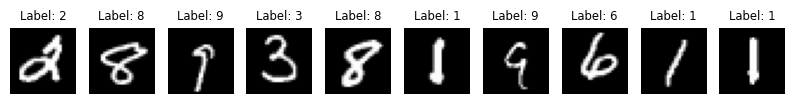

In [11]:
# Visualize the MNIST dataset
n = 10
idx = np.random.randint(0, len(train_dataset), size=n)
fig, ax = plt.subplots(1, n, figsize=(n, 1.5))
for i in range(n):
    image, label = train_dataset[idx[i]]
    ax[i].imshow(image.view(28, 28), cmap='gray')
    ax[i].set_title(f"Label: {label}")
    ax[i].axis('off')
plt.show()

In [12]:
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)
for i in range(10):
    print(f"Batch {i+1}:")
    batch_inputs, batch_targets = next(iter(train_loader))
    print('targets:', batch_targets)

Batch 1:
targets: tensor([8, 7, 2, 8, 1, 6, 7, 8, 1, 9, 7, 4, 5, 9, 1, 3, 3, 2, 5, 1, 0, 4, 3, 7,
        4, 5, 0, 7, 9, 7, 9, 2, 0, 9, 8, 2, 1, 0, 1, 7, 3, 8, 2, 2, 5, 6, 7, 5,
        0, 4, 0, 8, 2, 0, 8, 1, 2, 4, 8, 7, 3, 3, 0, 2])
Batch 2:
targets: tensor([1, 6, 7, 1, 5, 2, 8, 9, 8, 2, 3, 3, 4, 5, 2, 2, 7, 9, 1, 0, 8, 2, 1, 6,
        2, 5, 2, 8, 5, 6, 8, 9, 8, 3, 1, 6, 2, 8, 8, 2, 1, 7, 2, 6, 2, 1, 5, 2,
        2, 4, 9, 8, 8, 3, 4, 9, 7, 1, 1, 0, 3, 0, 1, 6])
Batch 3:
targets: tensor([0, 3, 1, 3, 5, 7, 1, 4, 0, 8, 8, 4, 8, 3, 6, 1, 5, 5, 0, 9, 2, 9, 5, 8,
        3, 0, 8, 4, 6, 7, 4, 0, 2, 2, 9, 9, 7, 1, 4, 2, 3, 2, 2, 3, 4, 7, 3, 1,
        9, 9, 6, 6, 2, 3, 2, 9, 1, 0, 5, 0, 3, 6, 4, 3])
Batch 4:
targets: tensor([0, 3, 5, 4, 1, 5, 2, 1, 9, 5, 7, 1, 9, 9, 6, 7, 7, 2, 8, 9, 7, 2, 2, 9,
        0, 7, 4, 2, 0, 0, 4, 9, 5, 2, 6, 3, 4, 1, 4, 0, 6, 8, 3, 2, 7, 0, 8, 3,
        2, 2, 2, 5, 0, 7, 1, 5, 4, 8, 1, 1, 5, 8, 4, 6])
Batch 5:
targets: tensor([3, 5, 6, 4, 7, 6, 1, 7, 3, 0, 8, 9

## 4. Training Functions


In [13]:
from json import load


def get_temperature(epoch, max_epoch):
    """
    Get temperature for Softmax/Gumbel-Softmax.
    """
    max_temp = 1.0
    min_temp = 0.01
    temperature = max_temp * (min_temp / max_temp) ** (epoch / max_epoch)
    return temperature

def train_model(model, train_dataset, test_dataset, epochs=100, lr=0.001, batch_size=64):
    """
    Train a model on the adding problem.
    """
    if isinstance(model, EISepNet):
        special_params, other_params = [], []
        for name, p in model.named_parameters():
            if name == "lstm.eimask_logit":   # 或者用 name.endswith("eimask_logit")
                special_params.append(p)
                # assert p.requires_grad, "eimask_logit should be trainable"
            else:
                other_params.append(p)
        optimizer = torch.optim.Adam([{'params': special_params, 'lr': lr},
                                      {'params': other_params, 'lr': lr}])
    else:
        # For SimpleNet, use a single learning rate
        optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()  # Use CrossEntropyLoss for classification

    train_losses = torch.zeros(epochs)
    test_every = 100
    test_losses = torch.zeros(epochs // test_every)

    model.train()
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)
    loader = iter(train_loader)
    for epoch in range(epochs):
        # print(epoch)
        # Training
        if isinstance(model, EISepNet):
            model.temperature = get_temperature(epoch, epochs)
            # if epoch % 100 == 0:
            #     print(f"Epoch {epoch}: Temperature = {model.temperature:.4f}")
            #     eimask = model.lstm.eimask_logit.detach().cpu().numpy()
            #     fig, ax = plt.subplots(1,1,figsize=(8, 2))
            #     ax.plot(eimask[:, 0], label='Excitatory', color='C1')
            #     ax.plot(eimask[:, 1], label='Inhibitory', color='C0')
            #     ax.set_title('EI mask')
            #     ax.set_xlabel('Neuron index')
            #     ax.set_ylabel('Logit value')
            #     ax.legend()
            #     plt.show()
            #     plt.close()
        total_train_loss = 0
        num_batches = 0

        # for batch_inputs, batch_targets in train_loader:
        # try:
        #     batch_inputs, batch_targets = next(loader)
        # except StopIteration:
        #     print('reload')
        #     train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
        #     loader = iter(train_loader)
        #     batch_inputs, batch_targets = next(loader)
        batch_inputs, batch_targets = next(iter(train_loader))
        # print('batch_targets:', batch_targets)
        batch_inputs = batch_inputs.to(device).transpose(0, 1)  # (seq_len, batch_size, input_size)
        # print('batch_targets:', batch_targets.shape)
        batch_targets = batch_targets.to(device)

        optimizer.zero_grad()

        # Forward pass
        outputs, eimask_logit, hidden = model(batch_inputs)

        # Use the last output for regression
        predictions = outputs[-1, :]  # Last time step, all batches

        decoding_loss = criterion(predictions, batch_targets)

        if model.entropy_loss:
            eimask_prob = F.softmax(eimask_logit, dim=-1)
            eimask_entropy = -torch.sum(eimask_prob * torch.log(eimask_prob + 1e-10), dim=-1)
            entropy_loss = torch.mean(eimask_entropy)  # Add entropy regularization
        else:
            entropy_loss = 0.0

        loss = 1 * entropy_loss + decoding_loss
        # Backward pass
        loss.backward()
        # Gradient clipping for stability
        # torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        # gradient_log[i, 0] = net.lstm.Wrec_free.grad.norm(2).item()
        if isinstance(model, DANN):
            model.update(lr=lr, max_grad_norm=None)
            model.zero_grad()
        elif isinstance(model, ColEI):
            model.update(lr=lr, max_grad_norm=10)
            model.zero_grad()
        elif isinstance(model, DBPN):
            model.update(optimizer)
            # model.zero_grad()
        else:
            optimizer.step()

        total_train_loss += loss.item()
        num_batches += 1

        avg_train_loss = total_train_loss / num_batches
        train_losses[epoch] = avg_train_loss

        # Testing
        if epoch % test_every == 0:
            model.eval()
            total_test_loss = 0
            total_test_acc = 0
            num_test_batches = 0

            with torch.no_grad():
                for batch_inputs, batch_targets in test_loader:
                    batch_inputs = batch_inputs.to(device).transpose(0, 1)
                    batch_targets = batch_targets.to(device)

                    outputs, _, hidden = model(batch_inputs)
                    predictions = outputs[-1, :]

                    loss = criterion(predictions, batch_targets)
                    total_test_loss += loss.item()
                    total_test_acc += (predictions.argmax(-1) == batch_targets).float().mean().item()
                    num_test_batches += 1

            avg_test_loss = total_test_loss / num_test_batches
            avg_test_acc = total_test_acc / num_test_batches
            test_losses[epoch // test_every] = avg_test_loss

            print(f'Epoch [{epoch:4d}/{epochs}], Train Loss: {avg_train_loss:.6f}, Test Loss: {avg_test_loss:.6f}, Test Acc: {avg_test_acc:.4f}')

            model.train()

    return train_losses, test_losses

def evaluate_model(model, test_loader):
    """
    Evaluate model performance on test set.
    """
    model.eval()
    total_loss = 0
    predictions = []
    targets = []

    criterion = nn.CrossEntropyLoss()

    with torch.no_grad():
        for batch_inputs, batch_targets in test_loader:
            batch_inputs = batch_inputs.to(device).transpose(0, 1)
            batch_targets = batch_targets.to(device)

            outputs, _, hidden = model(batch_inputs)
            preds = outputs[-1, :]

            loss = criterion(preds, batch_targets)
            total_loss += loss.item()

            predictions.extend(preds.cpu().numpy())
            targets.extend(batch_targets.cpu().numpy())

    avg_loss = total_loss / len(test_loader)
    acc = np.mean(np.array(predictions).argmax(-1) == np.array(targets))

    return avg_loss, acc, predictions, targets

## 5. Experiment: Compare Net vs SimpleNet


In [14]:
# Experiment parameters
n_seeds = 5
epochs = 3000
batch_size = 64
hidden_size = 64
input_size = 28//ROW_FACTOR  # [number, indicator]
output_size = 10  # regression output

# Create data loaders
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

# Storage for results
results = {
    'net': {'train_losses': [], 'test_losses': [], 'final_acc':[]},
    'simple': {'train_losses': [], 'test_losses': [], 'final_acc':[]}
}
ei_logit_arr = np.zeros((n_seeds, hidden_size, 2))
print(f"Running experiment with {n_seeds} seeds...\n")
lr_ei = 1e-2
# lr_simple = 1e-3
for seed in range(n_seeds):
    print(f"=== Seed {seed + 1}/{n_seeds} ===")

    # Set random seeds for reproducibility
    torch.manual_seed(seed+5)
    np.random.seed(seed+5)

    # Train Net (EI-separated RNN)
    print("Training Net (EI-separated RNN)...")
    # net = EISepNet(ob_size=input_size, num_h=hidden_size, act_size=output_size, entropy_loss=True).to(device)
    net = DBPN(ob_size=input_size, num_h=hidden_size, act_size=output_size).to(device)
    # net = ColEI(ob_size=input_size, num_h=hidden_size, act_size=output_size, optimizer='sgd').to(device)
    
    train_losses_net, test_losses_net = train_model(net, train_dataset, test_dataset, epochs=epochs, lr=lr_ei, batch_size=batch_size)

    # Evaluate Net
    _, acc_net, net_predictions, net_targets = evaluate_model(net, test_loader)

    results['net']['train_losses'].append(train_losses_net)
    results['net']['test_losses'].append(test_losses_net)
    results['net']['final_acc'].append(acc_net)
    print(f"Net - Final Acc: {acc_net:.6f}")




    # # Train SimpleNet (vanilla RNN)
    # print("Training SimpleNet (vanilla RNN)...")
    # simple_net = SimpleNet(ob_size=input_size, num_h=hidden_size, act_size=output_size).to(device)
    # train_losses_simple, test_losses_simple = train_model(simple_net, train_dataset, test_dataset, epochs=epochs,lr=lr_simple, batch_size=batch_size)

    # # Evaluate SimpleNet
    # _, acc_simple, simple_predictions, simple_targets = evaluate_model(simple_net, test_loader)

    # results['simple']['train_losses'].append(train_losses_simple.detach().cpu().numpy())
    # results['simple']['test_losses'].append(test_losses_simple.detach().cpu().numpy())
    # results['simple']['final_acc'].append(acc_simple)

    # print(f"SimpleNet - Final Acc: {acc_simple:.6f}")




print("Experiment completed!")

Running experiment with 5 seeds...

=== Seed 1/5 ===
Training Net (EI-separated RNN)...
Epoch [   0/3000], Train Loss: 2.480349, Test Loss: 2.368852, Test Acc: 0.0885
Epoch [ 100/3000], Train Loss: 2.373028, Test Loss: 2.307453, Test Acc: 0.1184
Epoch [ 200/3000], Train Loss: 1.716342, Test Loss: 1.850029, Test Acc: 0.2602
Epoch [ 300/3000], Train Loss: 1.819849, Test Loss: 1.744515, Test Acc: 0.3419
Epoch [ 400/3000], Train Loss: 1.649976, Test Loss: 1.791911, Test Acc: 0.3077
Epoch [ 500/3000], Train Loss: 1.977585, Test Loss: 1.723444, Test Acc: 0.3428
Epoch [ 600/3000], Train Loss: 1.737618, Test Loss: 1.732199, Test Acc: 0.3061
Epoch [ 700/3000], Train Loss: 1.685123, Test Loss: 1.705931, Test Acc: 0.3356
Epoch [ 800/3000], Train Loss: 1.859897, Test Loss: 1.775515, Test Acc: 0.3241
Epoch [ 900/3000], Train Loss: 1.911614, Test Loss: 1.668059, Test Acc: 0.3587
Epoch [1000/3000], Train Loss: 1.405146, Test Loss: 1.743039, Test Acc: 0.3215
Epoch [1100/3000], Train Loss: 1.482098, Te

0.47325999999999996 0.03744513853626397
(5, 3000)


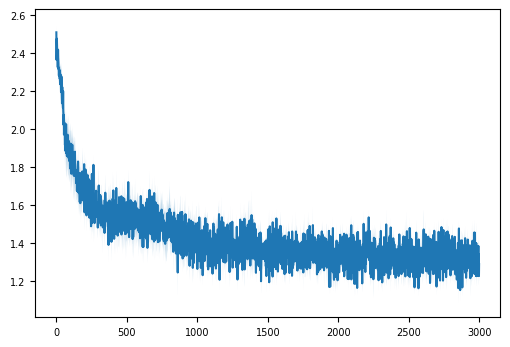

In [ ]:
final_acc = np.array(results['net']['final_acc'])
print(final_acc.mean(), final_acc.std())
# colei adam, no substracted by mean. 0.8339000000000001 0.013245376551838751
# colei adam, substracted. 0.8112 0.026416055723744954
# colei sgd, substracted. 0.51048 0.1609301885912025
# dbpn normalize, 0.3903 0.08628007881313045
# dbpn not substracted, 0.47325999999999996 0.03744513853626397
train_loss = np.array(results['net']['train_losses'])
print(train_loss.shape)
fig, ax = plt.subplots(1,1,figsize=(6,4))
mean_loss = train_loss.mean(0)
ste_loss = train_loss.std(0)/np.sqrt(train_loss.shape[0])
ax.plot(mean_loss, label='Mean Train Loss')
ax.fill_between(np.arange(len(mean_loss)), mean_loss - ste_loss, mean_loss + ste_loss, alpha=0.3)
plt.show()

TypeError: can't convert cuda:0 device type tensor to numpy. Use Tensor.cpu() to copy the tensor to host memory first.

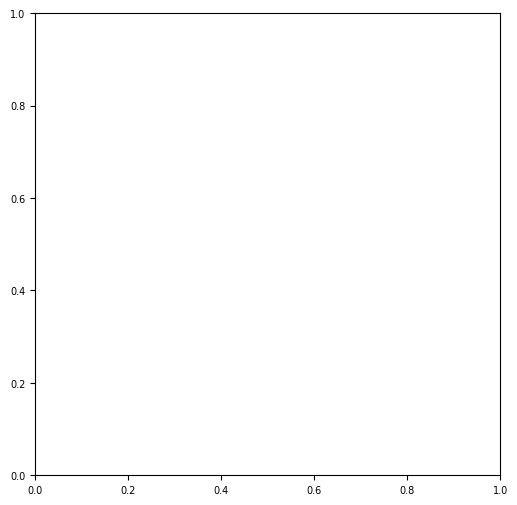

In [16]:
w = net.get_actual_weight()
fig, ax = plt.subplots(1,1,figsize=(6,6))
im = ax.imshow(w, cmap='bwr', vmin=-np.max(np.abs(w)), vmax=np.max(np.abs(w)))
ax.set_title('Recurrent Weight Matrix')
ax.set_xlabel('Neuron index')
ax.set_ylabel('Neuron index')

## 6. Results Analysis


In [ ]:
# Print summary statistics
print("=== Final Results Summary ===")
print(f"Number of seeds: {n_seeds}")
print(f"Training epochs: {epochs}")
print(f"Hidden size: {hidden_size}")
print()

# Net results
net_acc_mean = np.mean(results['net']['final_acc'])
net_acc_std = np.std(results['net']['final_acc'])
simple_acc_mean = np.mean(results['simple']['final_acc'])
simple_acc_std = np.std(results['simple']['final_acc'])

print(f"Net (EI-separated RNN):")
print(f"  Acc: {net_acc_mean:.6f} ± {net_acc_std:.6f}")

print(f"\nSimpleNet (vanilla RNN):")
print(f"  Acc: {simple_acc_mean:.6f} ± {simple_acc_std:.6f}")

# Improvement calculation
acc_improvement = (net_acc_mean - simple_acc_mean ) / simple_acc_mean * 100

print(f"\n=== Performance Comparison ===")
print(f"Acc improvement (Net vs SimpleNet): {acc_improvement:.2f}%")

if acc_improvement > 0:
    print("Net (EI-separated) performs better than SimpleNet (vanilla RNN)")
else:
    print("SimpleNet (vanilla RNN) performs better than Net (EI-separated)")

=== Final Results Summary ===
Number of seeds: 5
Training epochs: 5000
Hidden size: 64

Net (EI-separated RNN):
  Acc: 0.674720 ± 0.091305

SimpleNet (vanilla RNN):
  Acc: nan ± nan

=== Performance Comparison ===
Acc improvement (Net vs SimpleNet): nan%
SimpleNet (vanilla RNN) performs better than Net (EI-separated)


## 7. Visualization


net train mean: [2.4816942  2.4318347  2.4253983  ... 0.8371686  0.8847275  0.90589345]
(array([], dtype=int64), array([], dtype=int64))


ValueError: x and y must have same first dimension, but have shapes (5000,) and (1,)

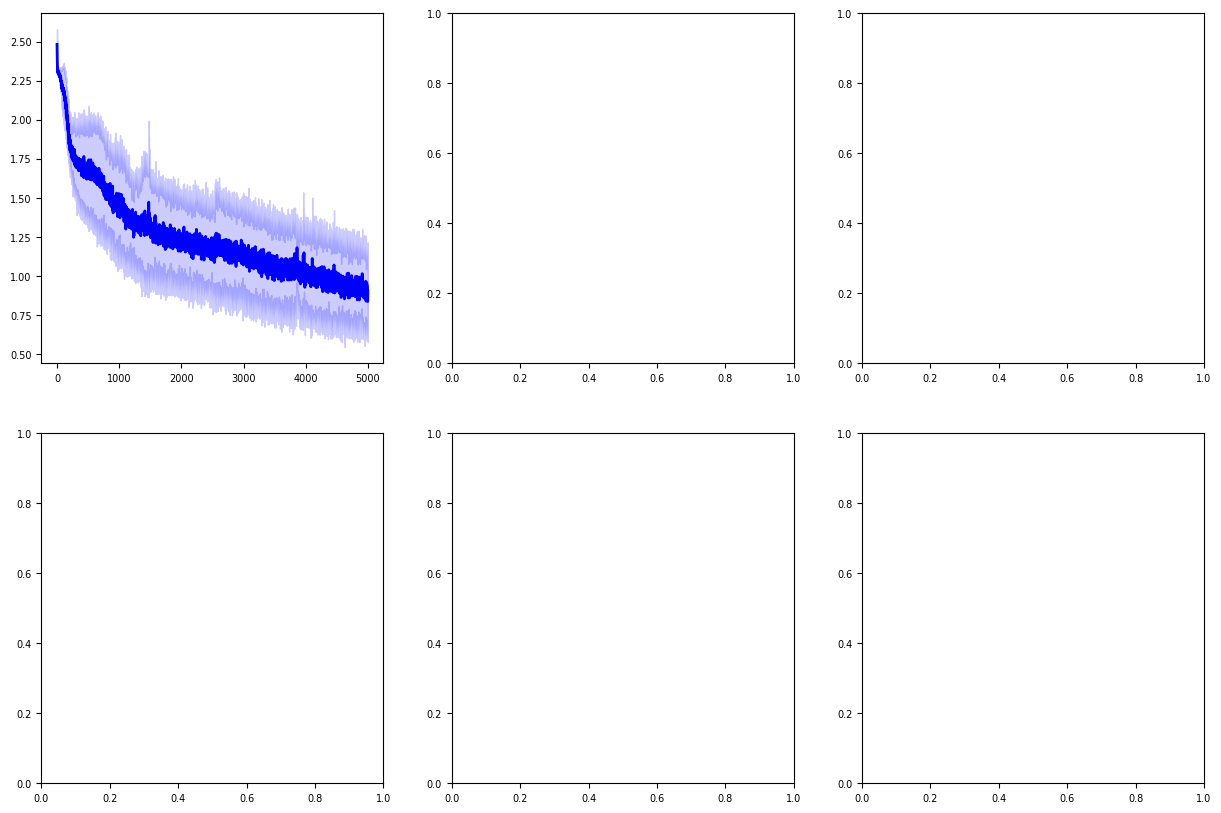

In [ ]:
def plot_learning_curves(results, n_seeds):
    """
    Plot learning curves for both models.
    """
    fig, ((ax1, ax2, ax3), (ax4, ax5, ax6)) = plt.subplots(2, 3, figsize=(15, 10))

    # Training loss curves
    net_train_losses = np.array(results['net']['train_losses'])
    simple_train_losses = np.array(results['simple']['train_losses'])

    net_train_mean = np.mean(net_train_losses, axis=0)
    net_train_std = np.std(net_train_losses, axis=0)
    simple_train_mean = np.mean(simple_train_losses, axis=0)
    simple_train_std = np.std(simple_train_losses, axis=0)
    print('net train mean:', net_train_mean)
    print(np.where(net_train_losses>100))

    epochs_range = range(len(net_train_mean))

    ax1.plot(epochs_range, net_train_mean, 'b-', label='Net (EI-separated)', linewidth=2)
    ax1.fill_between(epochs_range, net_train_mean - net_train_std, net_train_mean + net_train_std, alpha=0.2, color='blue')
    ax1.plot(epochs_range, simple_train_mean, 'r-', label='SimpleNet (vanilla)', linewidth=2)
    ax1.fill_between(epochs_range, simple_train_mean - simple_train_std, simple_train_mean + simple_train_std, alpha=0.2, color='red')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Training Loss (MSE)')
    ax1.set_title('Training Loss')
    ax1.legend()
    ax1.grid(True, alpha=0.3)
    ax1.set_yscale('log')

    # Test loss curves (subset of epochs)
    if results['net']['test_losses'][0] is not None:  # Check if test losses exist
        net_test_losses = np.array(results['net']['test_losses'])
        simple_test_losses = np.array(results['simple']['test_losses'])

        net_test_mean = np.mean(net_test_losses, axis=0)
        net_test_std = np.std(net_test_losses, axis=0)
        simple_test_mean = np.mean(simple_test_losses, axis=0)
        simple_test_std = np.std(simple_test_losses, axis=0)

        test_epochs = range(0, len(net_train_mean))[:len(net_test_mean)]

        ax2.plot(test_epochs, net_test_mean, 'b-', label='Net (EI-separated)', linewidth=2)
        ax2.fill_between(test_epochs, net_test_mean - net_test_std, net_test_mean + net_test_std, alpha=0.2, color='blue')
        ax2.plot(test_epochs, simple_test_mean, 'r-', label='SimpleNet (vanilla)', linewidth=2)
        ax2.fill_between(test_epochs, simple_test_mean - simple_test_std, simple_test_mean + simple_test_std, alpha=0.2, color='red')
        ax2.set_xlabel('Epoch')
        ax2.set_ylabel('Test Loss (MSE)')
        ax2.set_title('Test Loss')
        ax2.legend()
        ax2.grid(True, alpha=0.3)
        ax2.set_yscale('log')


    # Final Acc comparison
    net_acc = results['net']['final_acc']
    simple_acc = results['simple']['final_acc']

    x_pos = [0, 1]
    acc_means = [np.mean(net_acc), np.mean(simple_acc)]
    acc_stds = [np.std(net_acc)/np.sqrt(len(net_acc)), np.std(simple_acc)/np.sqrt(len(simple_acc))]

    bars = ax4.bar(x_pos, acc_means, yerr=acc_stds, capsize=5,
                   color=['blue', 'red'], alpha=0.7,
                   label=['Net (EI-separated)', 'SimpleNet (vanilla)'])
    ax4.set_ylabel('Final Acc')
    ax4.set_title('Final Test Acc Comparison')
    ax4.set_xticks(x_pos)
    ax4.set_xticklabels(['Net\n(EI-separated)', 'SimpleNet\n(vanilla)'])
    ax4.grid(True, alpha=0.3)

    # Add value labels on bars
    for i, (bar, mean, std) in enumerate(zip(bars, acc_means, acc_stds)):
        ax4.text(bar.get_x() + bar.get_width()/2, bar.get_height() + std + 0.001,
                f'{mean:.4f}±{std:.4f}', ha='center', va='bottom', fontsize=10)


    plt.tight_layout()
    plt.show()

# Plot the results
plot_learning_curves(results, n_seeds)

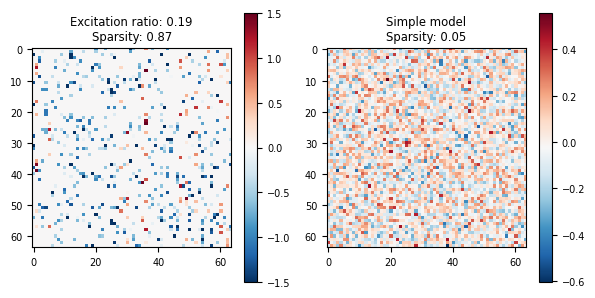

In [ ]:
weight = net.get_actual_weight().detach().cpu().numpy()
fig, ax = plt.subplots(1,2,figsize=(6,3))
limit = 1.5
im = ax[0].imshow(weight, cmap='RdBu_r', vmin=-limit, vmax=limit)
sparsity = 1 - np.mean(np.abs(weight)>0.1*np.std(np.abs(weight)))
eimask = net.lstm.eimask_logit.detach().cpu().numpy()
# mask = F.gumbel_softmax(net.lstm.eimask_logit, tau=0.1, hard=False, dim=-1).detach().cpu().numpy()
exc_ratio = np.mean(eimask[:, 0] > eimask[:, 1])
ax[0].set_title(f'Excitation ratio: {exc_ratio:.2f}\nSparsity: {sparsity:.2f}')
plt.colorbar(im, ax=ax[0])

weight_simple = simple_net.get_actual_weight().detach().cpu().numpy()
im = ax[1].imshow(weight_simple, cmap='RdBu_r')
sparsity_simple = 1 - np.mean(np.abs(weight_simple)>0.1*np.std(np.abs(weight_simple)))
ax[1].set_title(f'Simple model\nSparsity: {sparsity_simple:.2f}')
plt.colorbar(im, ax=ax[1])
plt.tight_layout()


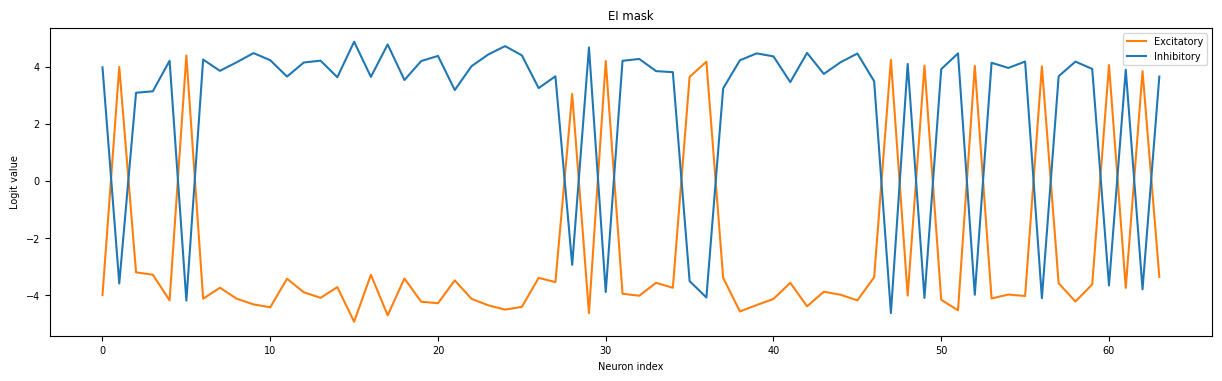

In [ ]:
eimask = net.lstm.eimask_logit.detach().cpu().numpy()
ei_code = np.where(eimask[:, 0] > eimask[:, 1], 1., -1.)
mask = np.where(ei_code.reshape(-1,1)>0, np.array([[1,0]]).repeat(eimask.shape[0], axis=0),
                np.array([[0,1]]).repeat(eimask.shape[0], axis=0))
fig, ax = plt.subplots(1,1,figsize=(15, 4))
ax.plot(eimask[:, 0], label='Excitatory', color='C1')
ax.plot(eimask[:, 1], label='Inhibitory', color='C0')
ax.set_title('EI mask')
ax.set_xlabel('Neuron index')
ax.set_ylabel('Logit value')
ax.legend()
plt.show()

## 8. Test Predictions Visualization


In [ ]:
n = 10
idx = np.random.randint(0, len(train_dataset), size=n)
fig, ax = plt.subplots(3, n, figsize=(n*1.5, 5))
for i in range(n):
    image, label = train_dataset[idx[i]]
    image_input = torch.FloatTensor(image.reshape(28*ROW_FACTOR,1,28//ROW_FACTOR)).to(device)
    net_predictions, _, _ = net(image_input)  # Add batch dimension
    simple_predictions, _, _ = simple_net(image_input)  # Add batch dimension
    net_distribution = F.softmax(net_predictions[-1,0]).detach().cpu().numpy()
    simple_distribution = F.softmax(simple_predictions[-1,0]).detach().cpu().numpy()
    net_label = net_distribution.argmax()
    simple_label = simple_distribution.argmax()
    ax[0, i].imshow(image.view(28, 28), cmap='gray')
    ax[0, i].set_title(f"Label: {label}")
    ax[0, i].axis('off')
    ax[1, i].bar(np.arange(output_size), net_distribution, color='blue', alpha=0.7)
    title_color = 'black' if net_label == label else 'red'
    ax[1, i].set_title(f"Net Prediction:{net_label}", color=title_color)
    ax[1, i].set_ylim(0, 1)
    ax[1, i].set_xticks(np.arange(output_size))
    ax[1, i].set_xticklabels(np.arange(output_size))
    ax[2, i].bar(np.arange(output_size), simple_distribution, color='red', alpha=0.7)
    title_color = 'black' if simple_label == label else 'red'
    ax[2, i].set_title(f"SimpleNet Prediction:{simple_label}", color=title_color)
    ax[2, i].set_ylim(0, 1)
    ax[2, i].set_xticks(np.arange(output_size))
    ax[2, i].set_xticklabels(np.arange(output_size))
plt.tight_layout()
plt.show()


KeyboardInterrupt: 